# Silero VAD
Quick look at one file and where the speech is. Silero needs 16 kHz.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import torch
import torchaudio
from IPython.display import Audio, display

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
wavs = sorted((root / "data" / "raw_audios").glob("*.wav"))
for i, p in enumerate(wavs):
    print(i, p.name)

0 18-35 yosh bo'lsangiz, shu 8ta darsni eshitishingiz kerak.wav
1 2026-yilda Google'ga ishga kirish XARITASI.wav
2 28-son - GTA VI, Fransiyadagi noroziliklar, Tesla uchar avtomobili va boshqa yangiliklar tahlili.wav
3 29-son - Krinjdan tortib siyosatgacha hafta davomida sodir bo‘lgan voqealar muhokamasi.wav
4 31 - son - Birinçi besoqol, musulmon, tub amerikalik senatorlar. Amerika siyosati kök rangda.wav
5 40 daqiqada yillar davomida yo'qotganimizni qaytaramiz - Maqolim 1-son.wav
6 50 yoshida ham studentlikni tanlaydigan odam bilan suhbat.wav
7 99% odamlar buni eplay olmaydi - Iqtibos podcast #27.wav
8 AQLI PASTlar avlodi (bo'lib qolyapmiz).wav
9 Afsus qilmaslik uchun bugun nima qilish kerak - Hasanxon Yahyo Abdulmajid.wav
10 Chegaralar torayayotganini his qildim - Jamshidxon Ziyoxonov.wav
11 Dasturchilik faoliyatimni yakunlayman! - Azim Pulat Gashtak podkastida.wav
12 Ertaga bankrot bo‘lmaslik uchun hozir nima qilish kerak - Alisher Isayev.wav
13 HOZIRGI YOSHLAR NIMADAN BOSHLASHI KERA

In [5]:
audio_path = wavs[3]
SR = 16000

audio, sr = sf.read(audio_path, dtype="float32", always_2d=True)
wav = torch.from_numpy(audio.T.copy()).mean(dim=0)
wav = torchaudio.functional.resample(wav, sr, SR)
print(f"{audio_path.name}: {len(wav) / SR:.1f}s")
display(Audio(wav[: 60 * SR].numpy(), rate=SR))  # first minute only

29-son - Krinjdan tortib siyosatgacha hafta davomida sodir bo‘lgan voqealar muhokamasi.wav: 2455.0s


In [6]:
model, utils = torch.hub.load("snakers4/silero-vad", "silero_vad", trust_repo=True)
get_speech_timestamps = utils[0]

speech = get_speech_timestamps(wav, model, sampling_rate=SR, return_seconds=True)
print(len(speech), "segments,", round(sum(s["end"] - s["start"] for s in speech), 1), "s speech")

Using cache found in /Users/macbook/.cache/torch/hub/snakers4_silero-vad_master
/Users/macbook/Documents/IT/projects/tts/.venv/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


129 segments, 2337.5 s speech


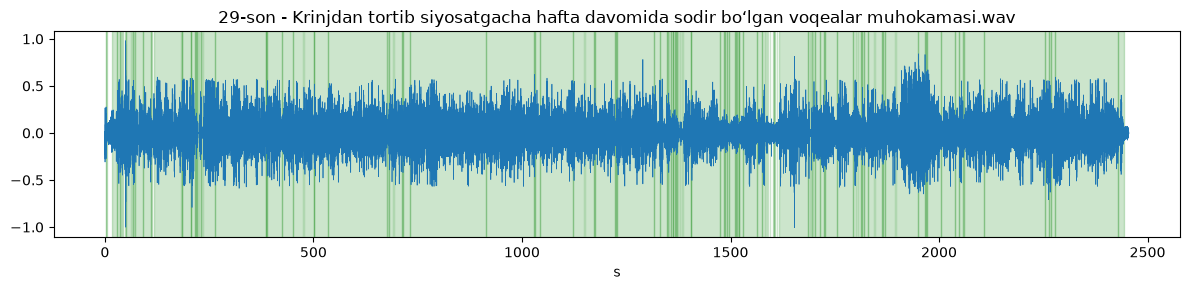

In [7]:
step = SR // 100
t = np.arange(0, len(wav), step) / SR
plt.figure(figsize=(12, 3))
plt.plot(t, wav[::step].numpy(), linewidth=0.5)
for s in speech:
    plt.axvspan(s["start"], s["end"], color="green", alpha=0.2)
plt.xlabel("s")
plt.title(audio_path.name)
plt.tight_layout()
plt.show()